In [134]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest

import joblib

import warnings
warnings.filterwarnings("ignore")

In [135]:
file_path = r"C:\Users\DEBRAJ\OneDrive\Desktop\PBL\data\ai4i2020.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10000, 14)


In [136]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [137]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [138]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [139]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [140]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


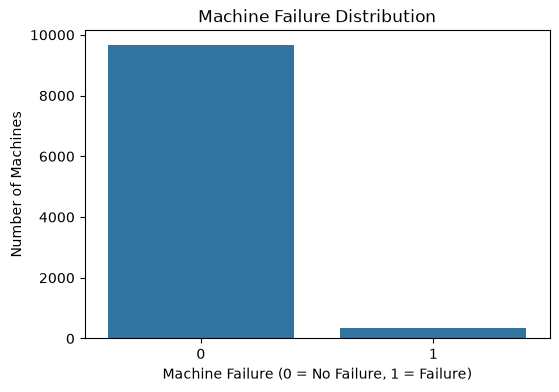

In [141]:
print(df["Machine failure"].value_counts())

print("\nPercentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Machines")

plt.show()

In [142]:
print(df.columns.tolist())

['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


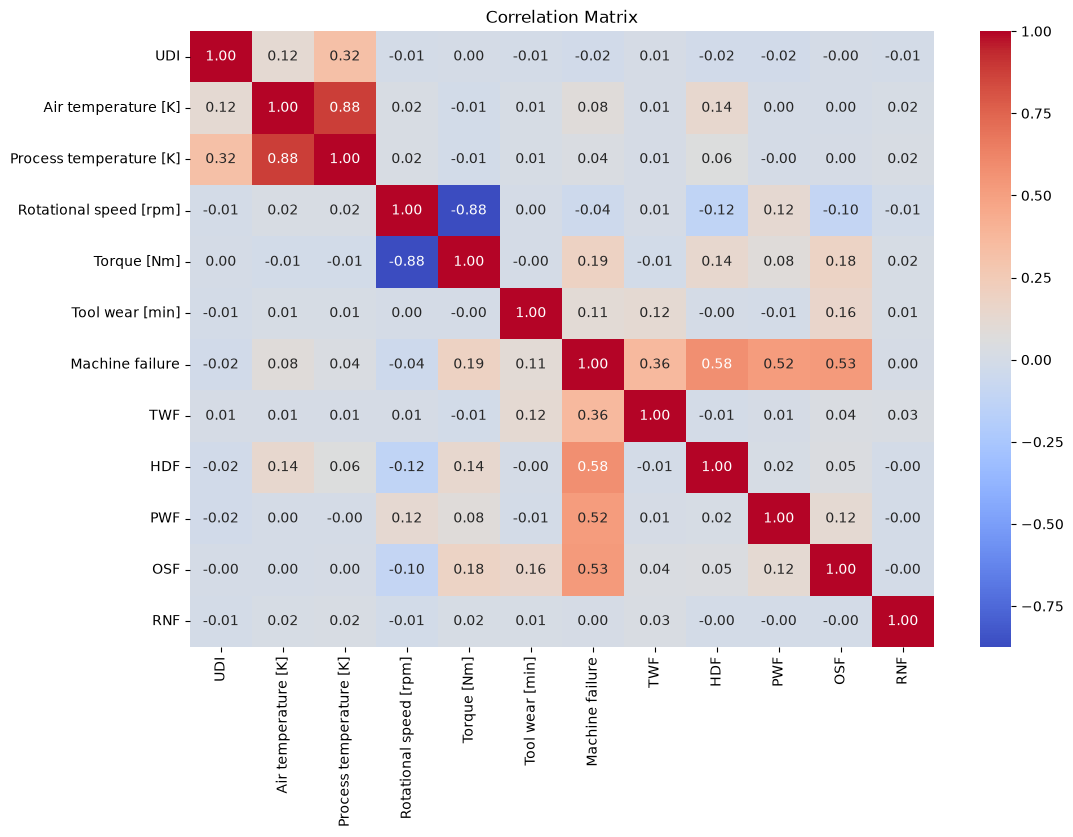

In [143]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

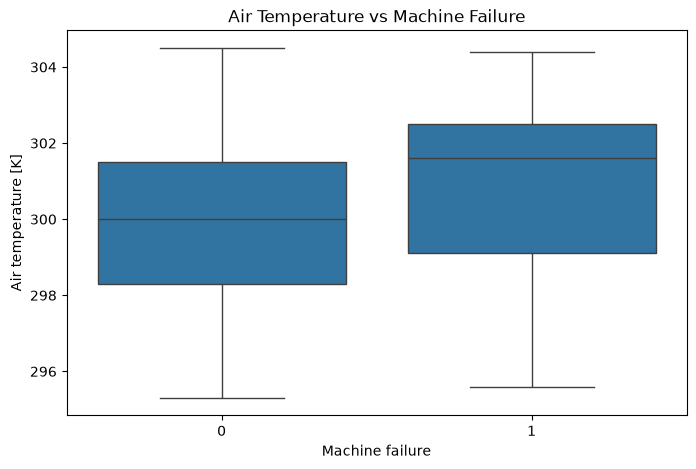

In [144]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Air temperature [K]"
)

plt.title("Air Temperature vs Machine Failure")

plt.show()

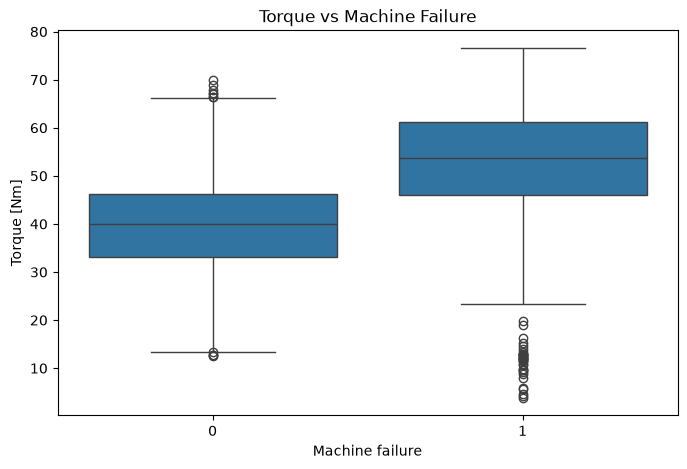

In [145]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]"
)

plt.title("Torque vs Machine Failure")

plt.show()

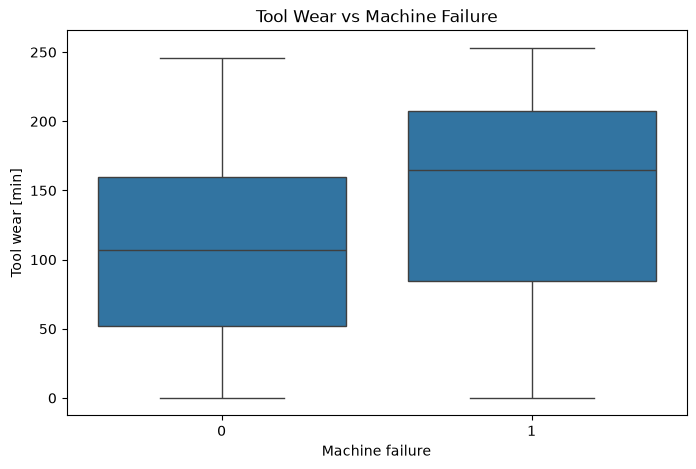

In [146]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Tool wear [min]"
)

plt.title("Tool Wear vs Machine Failure")

plt.show()

In [147]:
data = df.copy()

print("Original shape:", data.shape)

Original shape: (10000, 14)


In [148]:
data = data.drop(
    columns=["UDI", "Product ID"]
)

print(data.shape)

(10000, 12)


In [149]:
data = data.drop_duplicates()

print("Shape after removing duplicates:", data.shape)

Shape after removing duplicates: (10000, 12)


In [150]:
# Convert Product Type into numerical columns
data = pd.get_dummies(
    data,
    columns=["Type"],
    drop_first=True
)

# Clean column names for machine learning models
data.columns = (
    data.columns
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
    .str.replace("<", "", regex=False)
    .str.replace(" ", "_")
)

print(data.columns.tolist())

['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Type_L', 'Type_M']


In [151]:
# Separate features and target

X = data.drop(
    columns=[
        "Machine_failure",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ]
)

y = data["Machine_failure"]

print("Features:")
print(X.columns.tolist())

print("\nNumber of features:", X.shape[1])
print("Target shape:", y.shape)

Features:
['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Type_L', 'Type_M']

Number of features: 7
Target shape: (10000,)


In [152]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 7)
Testing data: (2000, 7)


In [153]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [154]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [155]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [156]:
!pip install xgboost


In [157]:
from xgboost import XGBClassifier

In [158]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("Scale Pos Weight:", scale_pos_weight)

Negative samples: 7729
Positive samples: 271
Scale Pos Weight: 28.52029520295203


In [159]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [160]:
def evaluate_model(model, X_test_data, y_test_data, model_name):
    
    predictions = model.predict(X_test_data)
    probabilities = model.predict_proba(X_test_data)[:, 1]
    
    accuracy = accuracy_score(y_test_data, predictions)
    precision = precision_score(y_test_data, predictions)
    recall = recall_score(y_test_data, predictions)
    f1 = f1_score(y_test_data, predictions)
    roc_auc = roc_auc_score(y_test_data, probabilities)
    
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC-AUC  :", round(roc_auc, 4))
    
    print("\nClassification Report:")
    print(classification_report(y_test_data, predictions))
    
    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

In [161]:
results = []

logistic_results = evaluate_model(
    logistic_model,
    X_test_scaled,
    y_test,
    "Logistic Regression"
)

results.append(logistic_results)

Logistic Regression
Accuracy : 0.8245
Precision: 0.1418
Recall   : 0.8235
F1 Score : 0.2419
ROC-AUC  : 0.907

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



In [162]:
rf_results = evaluate_model(
    rf_model,
    X_test,
    y_test,
    "Random Forest"
)

results.append(rf_results)

Random Forest
Accuracy : 0.982
Precision: 0.75
Recall   : 0.7059
F1 Score : 0.7273
ROC-AUC  : 0.9701

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.75      0.71      0.73        68

    accuracy                           0.98      2000
   macro avg       0.87      0.85      0.86      2000
weighted avg       0.98      0.98      0.98      2000



In [163]:
xgb_results = evaluate_model(
    xgb_model,
    X_test,
    y_test,
    "XGBoost"
)

results.append(xgb_results)

XGBoost
Accuracy : 0.9795
Precision: 0.6627
Recall   : 0.8088
F1 Score : 0.7285
ROC-AUC  : 0.9701

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.66      0.81      0.73        68

    accuracy                           0.98      2000
   macro avg       0.83      0.90      0.86      2000
weighted avg       0.98      0.98      0.98      2000



In [164]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8245,0.141772,0.823529,0.241901,0.906954
1,Random Forest,0.9820,0.750000,0.705882,0.727273,0.970052
2,XGBoost,0.9795,0.662651,0.808824,0.728477,0.970086


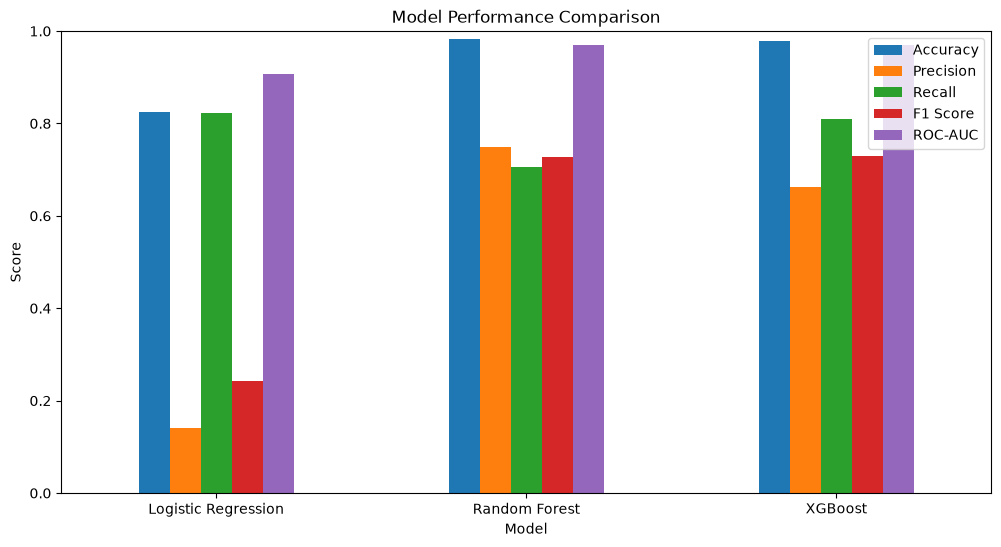

In [165]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend()

plt.show()

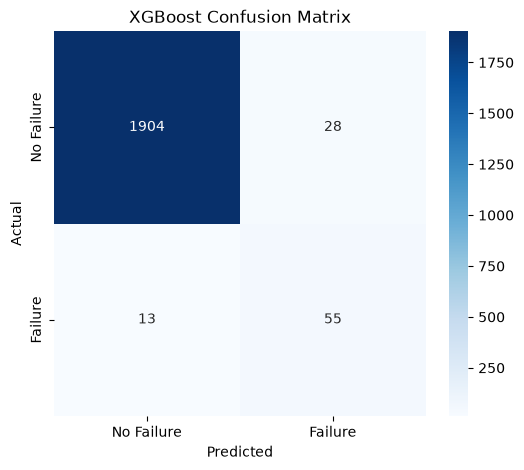

In [166]:
xgb_predictions = xgb_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    xgb_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("XGBoost Confusion Matrix")

plt.show()

In [167]:
logistic_prob = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

xgb_prob = xgb_model.predict_proba(
    X_test
)[:, 1]

In [168]:
fpr_log, tpr_log, _ = roc_curve(
    y_test,
    logistic_prob
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_prob
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    xgb_prob
)

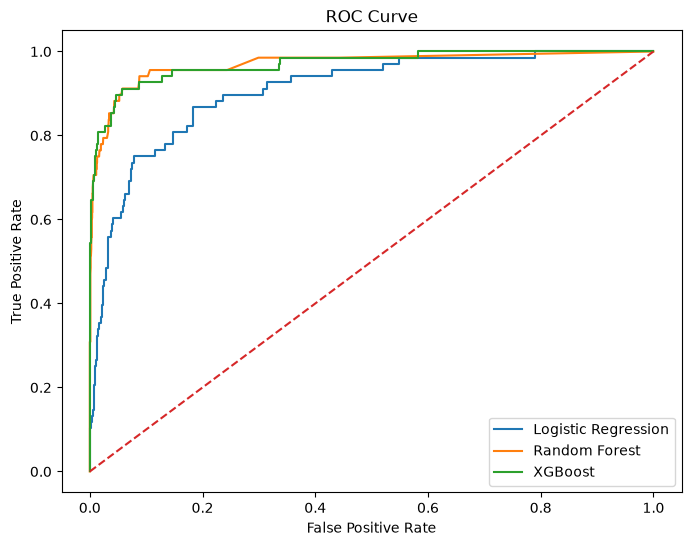

In [169]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label="Logistic Regression"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [170]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
3,Torque_Nm,0.326975
2,Rotational_speed_rpm,0.284763
4,Tool_wear_min,0.210992
0,Air_temperature_K,0.097974
1,Process_temperature_K,0.063715
5,Type_L,0.008949
6,Type_M,0.006632


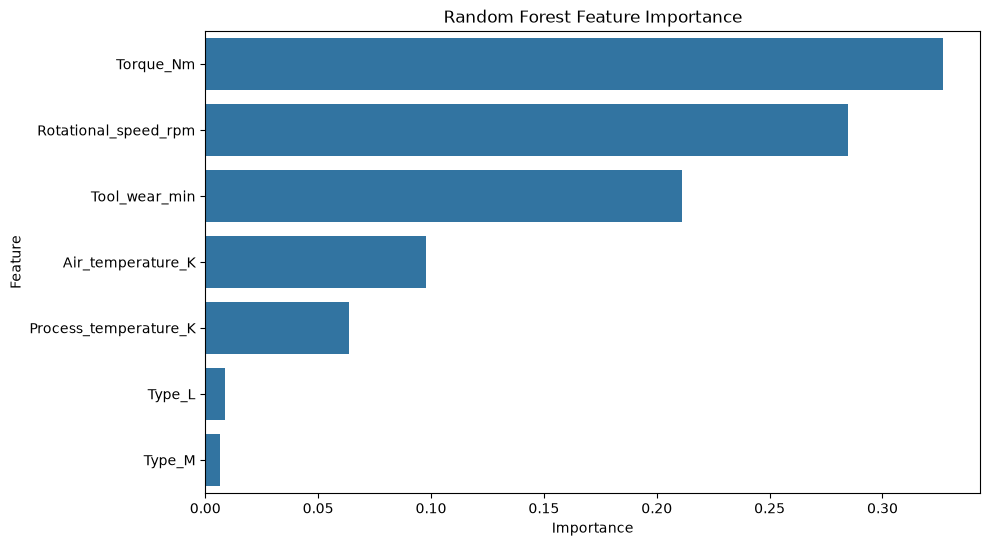

In [171]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.show()

In [172]:
!pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 6.7 MB/s  0:00:00

   ---------------------------------------- 0/3 [tqdm]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]



In [173]:
import shap

In [174]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

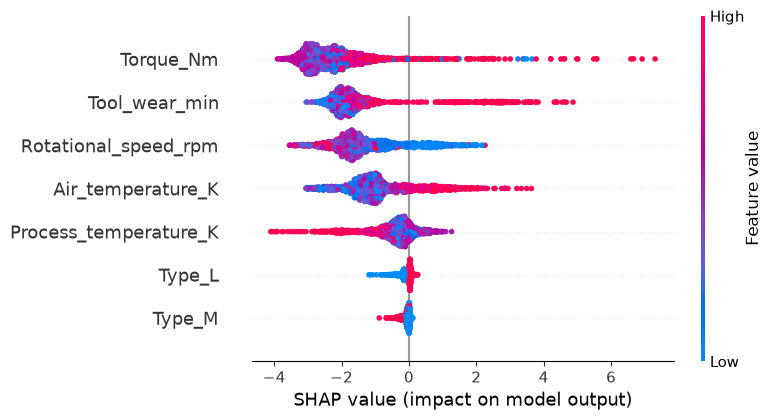

In [175]:
shap.summary_plot(
    shap_values,
    X_test
)

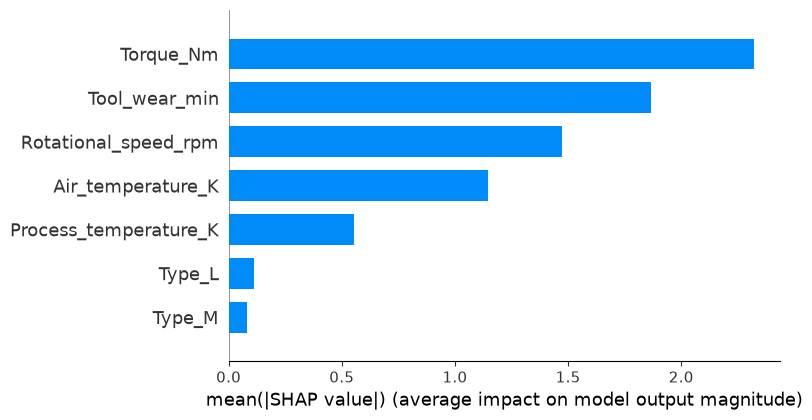

In [176]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

In [177]:
sample_index = 0

sample = X_test.iloc[[sample_index]]

prediction = xgb_model.predict(sample)[0]

probability = xgb_model.predict_proba(sample)[0][1]

print("Predicted Failure:", prediction)

print(
    "Failure Probability:",
    round(probability * 100, 2),
    "%"
)

Predicted Failure: 0
Failure Probability: 38.05 %


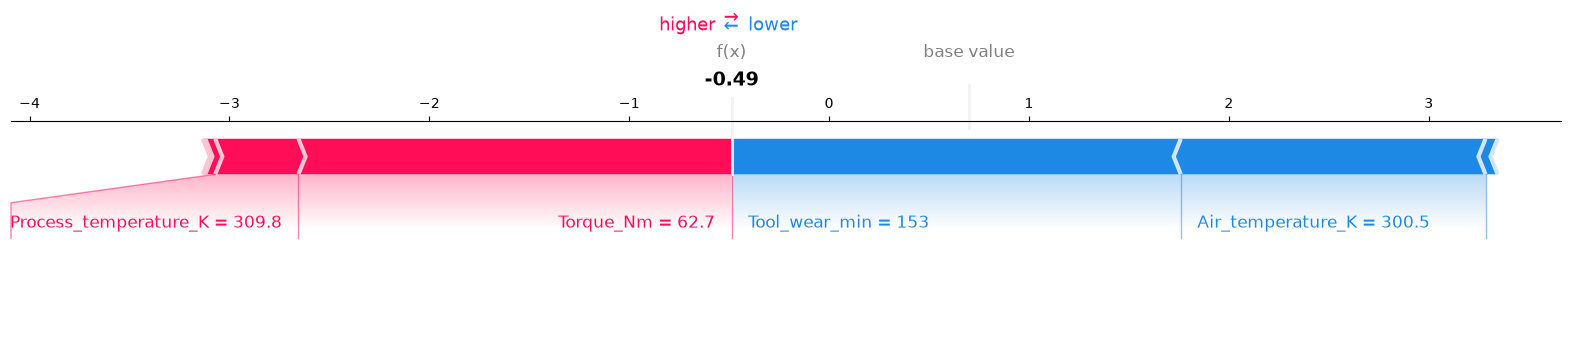

In [178]:
shap.force_plot(
    explainer.expected_value,
    explainer.shap_values(sample)[0],
    sample,
    matplotlib=True
)

In [179]:
anomaly_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_model.fit(X_train)

print("Anomaly detection model trained successfully!")

Anomaly detection model trained successfully!


In [180]:
anomaly_predictions = anomaly_model.predict(X_test)

anomaly_labels = np.where(
    anomaly_predictions == -1,
    1,
    0
)

print("Normal machines:", (anomaly_labels == 0).sum())
print("Anomalies:", (anomaly_labels == 1).sum())

Normal machines: 1902
Anomalies: 98


In [181]:
anomaly_results = X_test.copy()

anomaly_results["Anomaly"] = anomaly_labels

anomaly_results.head()

,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Type_L,Type_M,Anomaly
2997,300.5,309.8,1345,62.7,153,True,False,0
4871,303.7,312.4,1513,40.1,135,True,False,0
3858,302.5,311.4,1559,37.6,209,True,False,0
951,295.6,306.3,1509,35.8,60,False,False,1
6463,300.5,310.0,1358,60.4,102,False,False,0


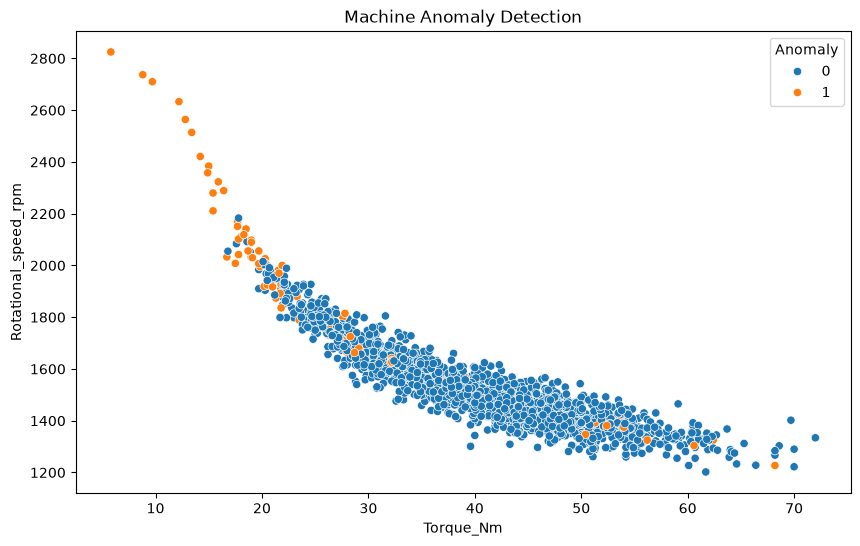

In [182]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=anomaly_results,
    x="Torque_Nm",
    y="Rotational_speed_rpm",
    hue="Anomaly"
)

plt.title("Machine Anomaly Detection")

plt.show()

In [183]:
risk_scores = (
    xgb_model.predict_proba(X_test)[:, 1] * 100
)

risk_results = X_test.copy()

risk_results["Failure_Risk_Percentage"] = risk_scores

risk_results["Predicted_Failure"] = (
    xgb_model.predict(X_test)
)

risk_results.head()

,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Type_L,Type_M,Failure_Risk_Percentage,Predicted_Failure
2997,300.5,309.8,1345,62.7,153,True,False,38.049114,0
4871,303.7,312.4,1513,40.1,135,True,False,0.126162,0
3858,302.5,311.4,1559,37.6,209,True,False,17.053179,0
951,295.6,306.3,1509,35.8,60,False,False,0.253101,0
6463,300.5,310.0,1358,60.4,102,False,False,15.978662,0


In [184]:
def risk_category(score):
    
    if score < 30:
        return "Low Risk"
    
    elif score < 70:
        return "Medium Risk"
    
    else:
        return "High Risk"


risk_results["Risk_Level"] = (
    risk_results["Failure_Risk_Percentage"]
    .apply(risk_category)
)

risk_results.head()

,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Type_L,Type_M,Failure_Risk_Percentage,Predicted_Failure,Risk_Level
2997,300.5,309.8,1345,62.7,153,True,False,38.049114,0,Medium Risk
4871,303.7,312.4,1513,40.1,135,True,False,0.126162,0,Low Risk
3858,302.5,311.4,1559,37.6,209,True,False,17.053179,0,Low Risk
951,295.6,306.3,1509,35.8,60,False,False,0.253101,0,Low Risk
6463,300.5,310.0,1358,60.4,102,False,False,15.978662,0,Low Risk


In [185]:
import os

os.makedirs("models", exist_ok=True)

print("Models folder ready.")

Models folder ready.


In [186]:
joblib.dump(
    xgb_model,
    "models/xgboost_model.pkl"
)

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


In [187]:
joblib.dump(
    scaler,
    "models/scaler.pkl"
)

print("Scaler saved successfully.")

Scaler saved successfully.


In [188]:
joblib.dump(
    anomaly_model,
    "models/anomaly_model.pkl"
)

print("Anomaly model saved successfully.")

Anomaly model saved successfully.


In [189]:
print("=" * 60)
print("        MACHINEGUARD - PREDICTIVE MAINTENANCE")
print("=" * 60)

print("\nDataset:")
print("Total samples:", len(df))

print("\nFeatures used:")
for feature in X.columns:
    print("-", feature)

print("\nModels trained:")
print("1. Logistic Regression")
print("2. Random Forest")
print("3. XGBoost")

print("\nAdvanced AI:")
print("✓ SHAP Explainability")
print("✓ Isolation Forest Anomaly Detection")

best_model = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

print("\nBest Model based on F1 Score:")
print(best_model)

print("\nMachineGuard pipeline completed successfully!")

        MACHINEGUARD - PREDICTIVE MAINTENANCE

Dataset:
Total samples: 10000

Features used:
- Air_temperature_K
- Process_temperature_K
- Rotational_speed_rpm
- Torque_Nm
- Tool_wear_min
- Type_L
- Type_M

Models trained:
1. Logistic Regression
2. Random Forest
3. XGBoost

Advanced AI:
✓ SHAP Explainability
✓ Isolation Forest Anomaly Detection

Best Model based on F1 Score:
XGBoost

MachineGuard pipeline completed successfully!


In [190]:
import os

os.makedirs("reports/figures", exist_ok=True)

print("Reports folder ready.")

Reports folder ready.


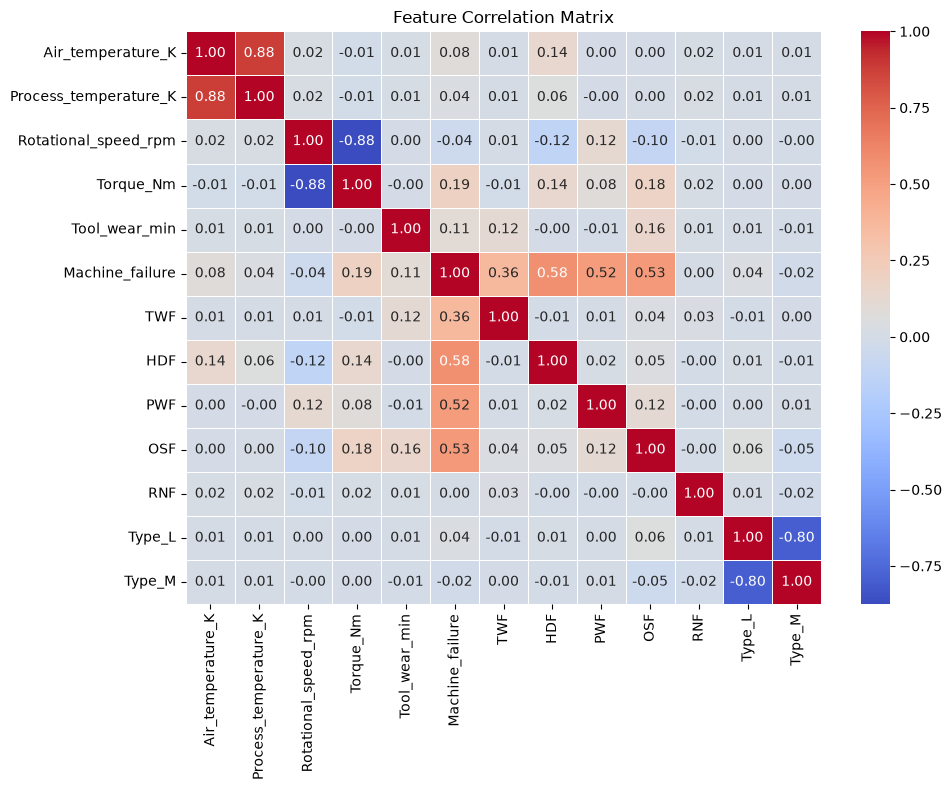

In [191]:
plt.figure(figsize=(10, 8))

correlation = data.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()

plt.savefig(
    "reports/figures/correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

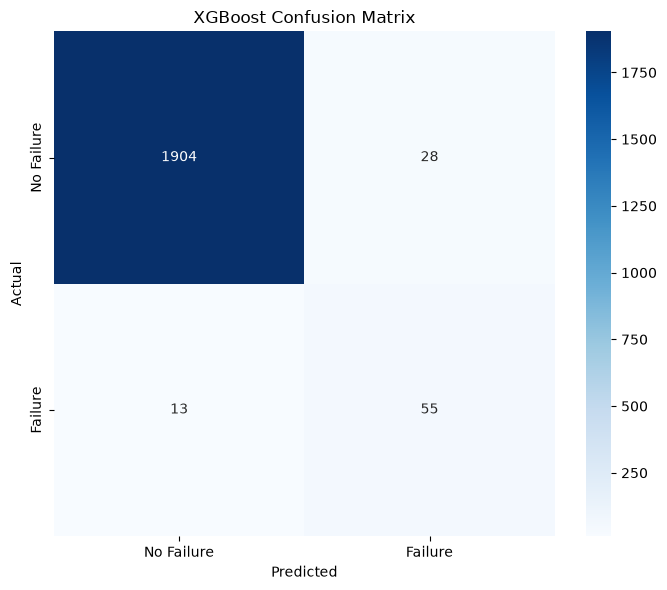

In [192]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "reports/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

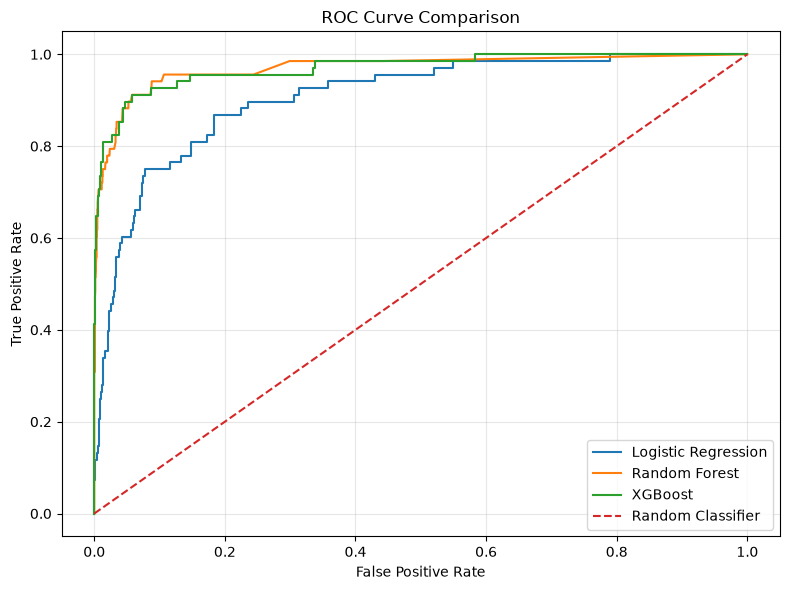

In [193]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label="Logistic Regression"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "reports/figures/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

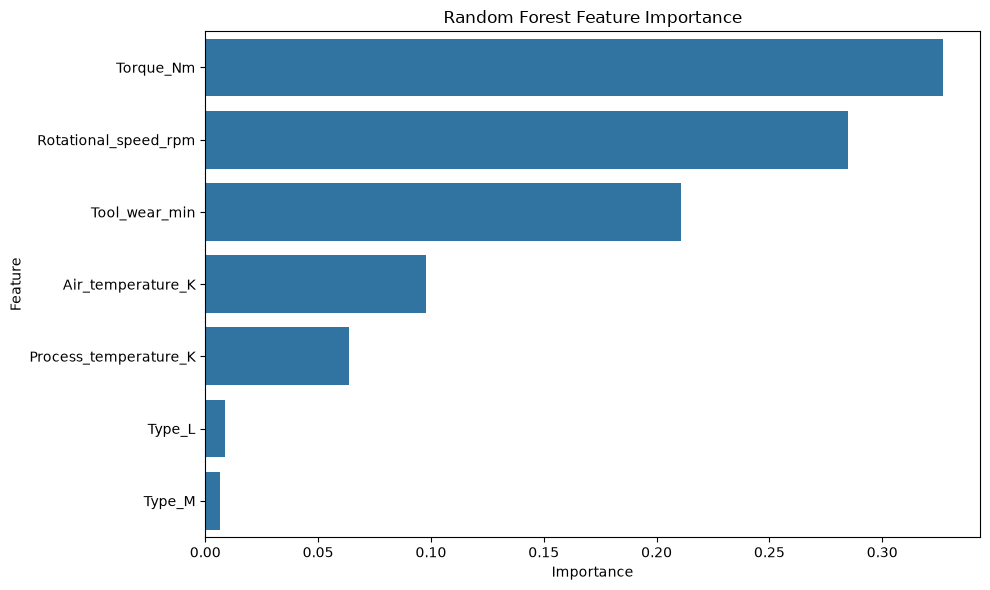

In [194]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

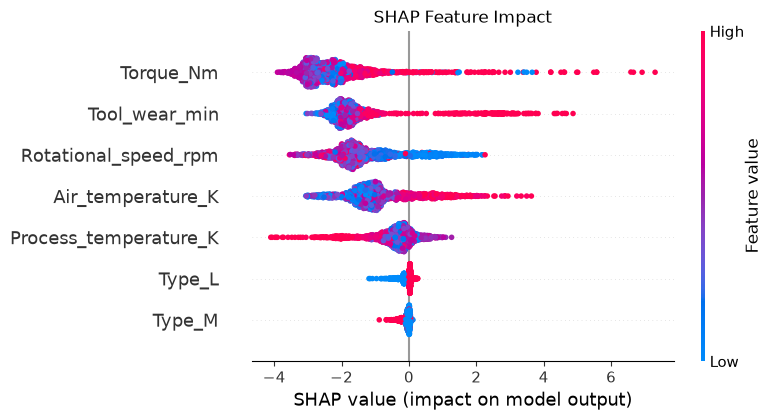

In [195]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title("SHAP Feature Impact")

plt.tight_layout()

plt.savefig(
    "reports/figures/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()